# DSCI 552 - Homework 6

- **Name:** Jesse Fulcher
- **GitHub Username:** jfulch
- **USC ID:** 7451-9585-45

## AI Use Disclosure

I used GitHub Copilot in VS Code (with GPT-6.1 Sol, GPT-6 Luna, and Claude Opus 5.5) for this homework.

- **Code:** Copilot assisted in by suggesting some of the code for data loading, median imputation, CV calculations, plots, the random forests, the XGBoost cross-validation, and the SMOTE implementation. I wrote SMOTE by hand with scikit-learn because I couldn't install `imbalanced-learn`. Copilot also helped me debug errors (for example, a wrong grid search parameter and a variable name conflict).

- **Written answers:** Copilot explained the methods and helped me understand concepts. It also helped simplify my answers using my notebook results.

- **ISLR 6.6.3, 6.6.5, 8.4.5, and 9.7.3:** Copilot explained the concepts and made suggestions for how to implement the 9.7.3 plot code. 

- **Repository files:** Copilot helped write the README, requirements.txt, and .gitignore.

I ran every cell, checked the numbers in my answers against the notebook outputs, and edited the code and text myself.

## 1. Tree-Based Methods

### 1(a) - Download the APS Failure data from: https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks . The dataset contains a training set and a test set. The training set contains 60,000 rows, of which 1,000 belong to the positive class and 171 columns, of which one is the class column. All attributes are nu-meric.

In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data")

train_df = pd.read_csv(
    data_dir / "aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    data_dir / "aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

print("Training Shape: ", train_df.shape)
print("Testing Shape: ", test_df.shape)
print("Training Class Counts:")
print(train_df["class"].value_counts())

display(train_df.head())

Training Shape:  (60000, 171)
Testing Shape:  (16000, 171)
Training Class Counts:
class
neg    59000
pos     1000
Name: count, dtype: int64


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### 1(b) - Data Preparation - This data set has missing values. When the number of data with missing values is significant, discarding them is not a good idea. 

#### 1(b)(i) - Research what types of techniques are usually used for dealing with data with missing values. Pick at least one of them and apply it to this data in the next steps.

In [2]:
from sklearn.impute import SimpleImputer

x_train_raw = train_df.drop(columns=["class"])
x_test_raw = test_df.drop(columns=["class"])

y_train = train_df["class"].copy()
y_test = test_df["class"].copy()

imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

x_train = pd.DataFrame(
    imputer.fit_transform(x_train_raw),
    columns=x_train_raw.columns,
    index=x_train_raw.index
)

x_test = pd.DataFrame(
    imputer.transform(x_test_raw),
    columns=x_test_raw.columns,
    index=x_test_raw.index
)

print("Training missing values before:", x_train_raw.isna().sum().sum())
print("Training missing values after:", x_train.isna().sum().sum())
print("Test missing values before:", x_test_raw.isna().sum().sum())
print("Test missing values after:", x_test.isna().sum().sum())

Training missing values before: 850015
Training missing values after: 0
Test missing values before: 228680
Test missing values after: 0


**Answer**: Common ways to fill missing values include using a features mean or median, using values from similar observations or predicting missing values from other features. I chose median imputation becasue it is simple, fast and less affected by extreme values than the mean.

#### 1(b)ii. For each of the 170 features, calculate the coefficient of variation CV = sm ,where s is sample standard deviation and m is sample mean.

In [3]:
import numpy as np
import pandas as pd

feature_means = x_train.mean()
feature_stds = x_train.std(ddof=1)

cv_table = pd.DataFrame({
    "Mean": feature_means,
    "Sample Standard Deviation": feature_stds,
    "CV": feature_stds / feature_means.replace(0, np.nan)
})

display(cv_table)

,Mean,Sample Standard Deviation,CV
aa_000,5.933650e+04,1.454301e+05,2.450938
ab_000,1.625000e-01,1.687318e+00,10.383494
ac_000,3.362258e+08,7.767625e+08,2.310241
ad_000,1.434383e+05,3.504525e+07,244.322816
ae_000,6.535000e+00,1.581479e+02,24.200137
...,...,...,...
ee_007,3.428586e+05,1.718666e+06,5.012754
ee_008,1.372212e+05,4.472145e+05,3.259079
ee_009,8.295099e+03,4.721249e+04,5.691612
ef_000,8.646667e-02,4.268570e+00,49.366659


#### 1(b)(iii) - Plot a correlation matrix for your features using pandas or any other tool.

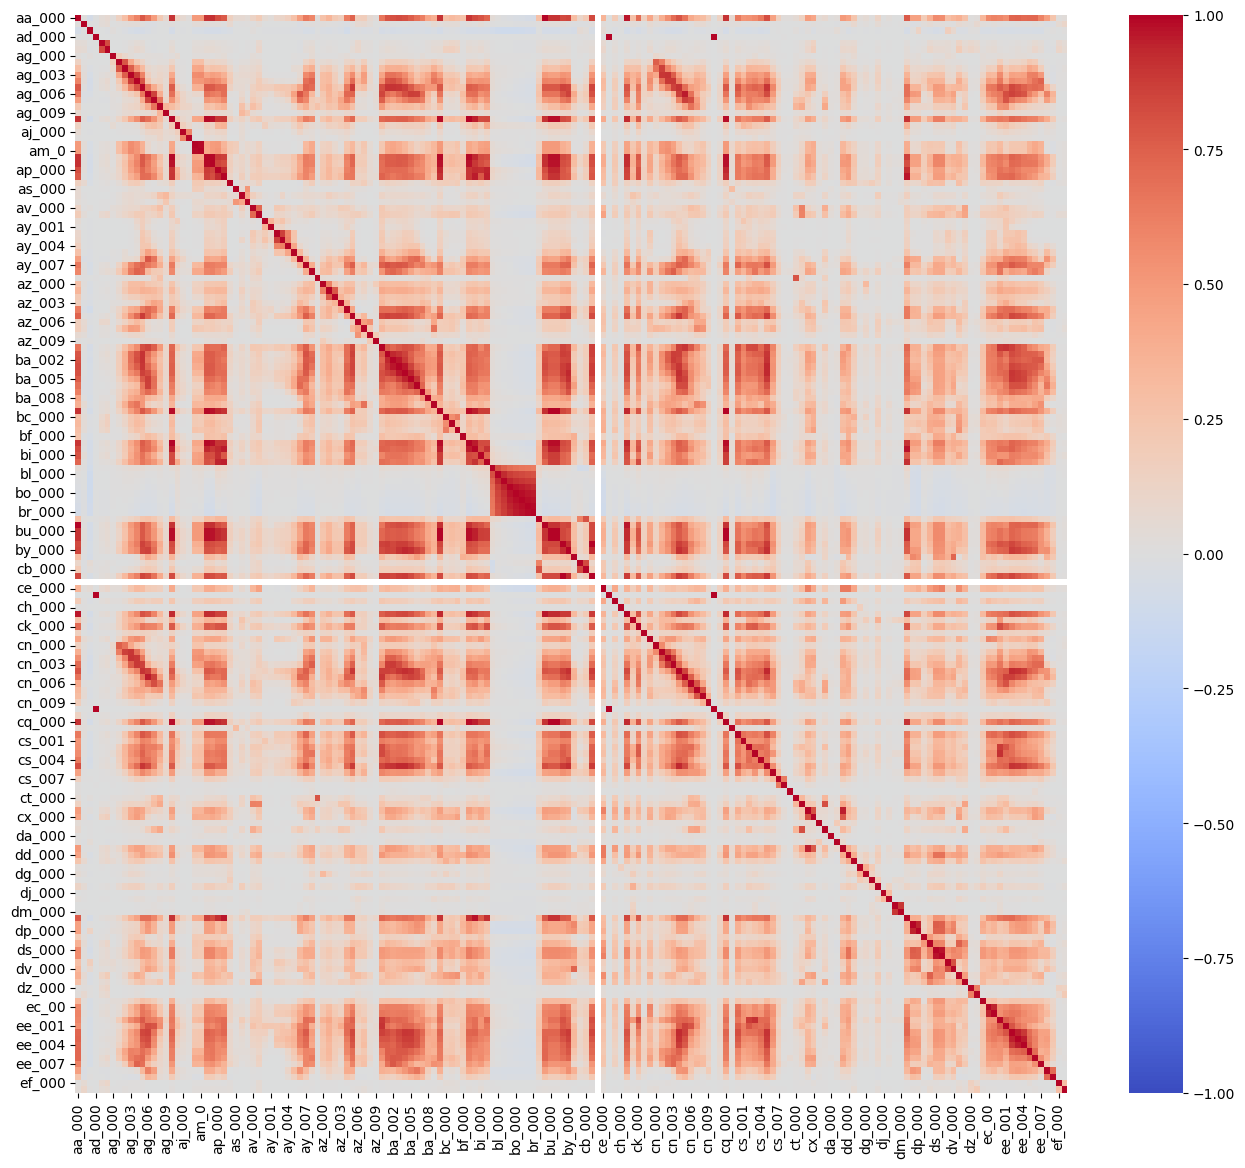

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = x_train.corr()

plt.figure(figsize=(16, 14))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.show()

#### 1(b)(iv) - Pick b√170c features with highest CV , and make scatter plots and box plotsfor them, similar to those on p. 129 of ISLR. Can you draw conclusions aboutsignificance of those features, just by the scatter plots? This does not meanthat you will only use those features in the following questions. We picked them only for visualization.

In [5]:
import numpy as np

n_features = int(np.sqrt(170))

top_features = (
    cv_table["CV"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .nlargest(n_features)
    .index
)

display(cv_table.loc[top_features].sort_values("CV", ascending=False))

,Mean,Sample Standard Deviation,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


In [6]:
import numpy as np

n_features = int(np.sqrt(170))

top_features = (
    cv_table["CV"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .nlargest(n_features)
    .index
)

display(cv_table.loc[top_features].sort_values("CV", ascending=False))

,Mean,Sample Standard Deviation,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


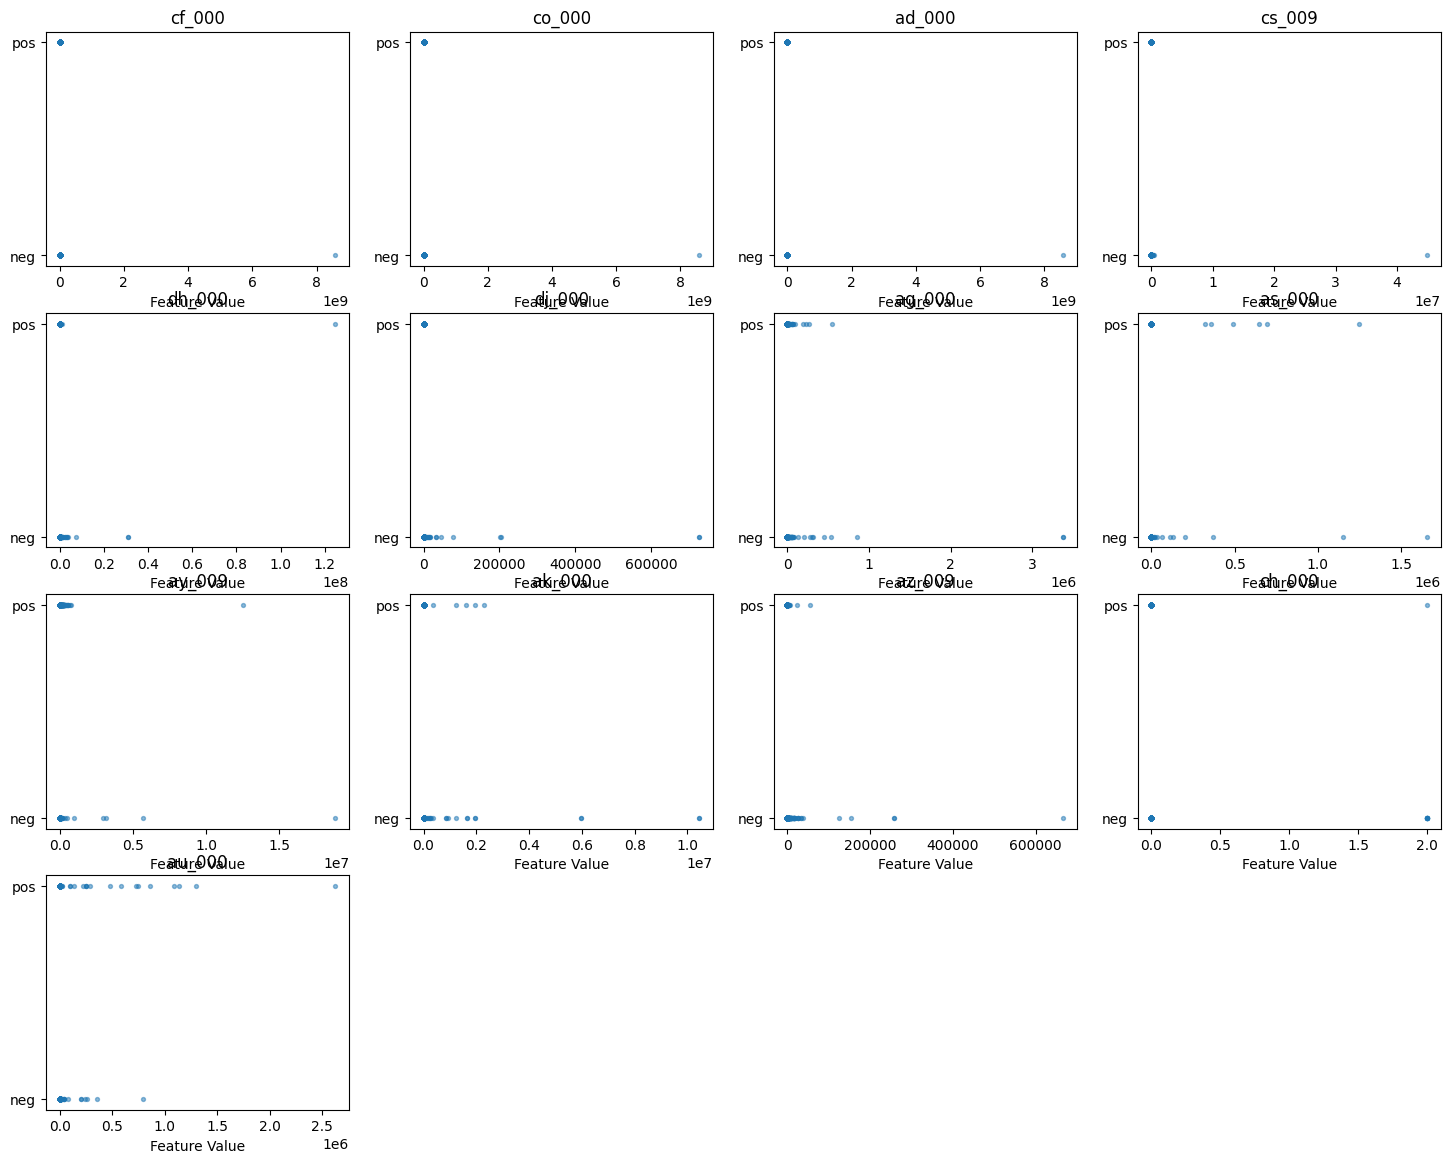

In [7]:
y_binary = y_train.map({"neg": 0, "pos": 1})

fig, axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, feature in zip(axes.flat, top_features):
    ax.scatter(
        x_train[feature],
        y_binary,
        alpha=0.5,
        s=8
    )
    ax.set_title(feature)
    ax.set_xlabel("Feature Value")
    ax.set_yticks([0, 1], labels=["neg", "pos"])

for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)

plt.show()

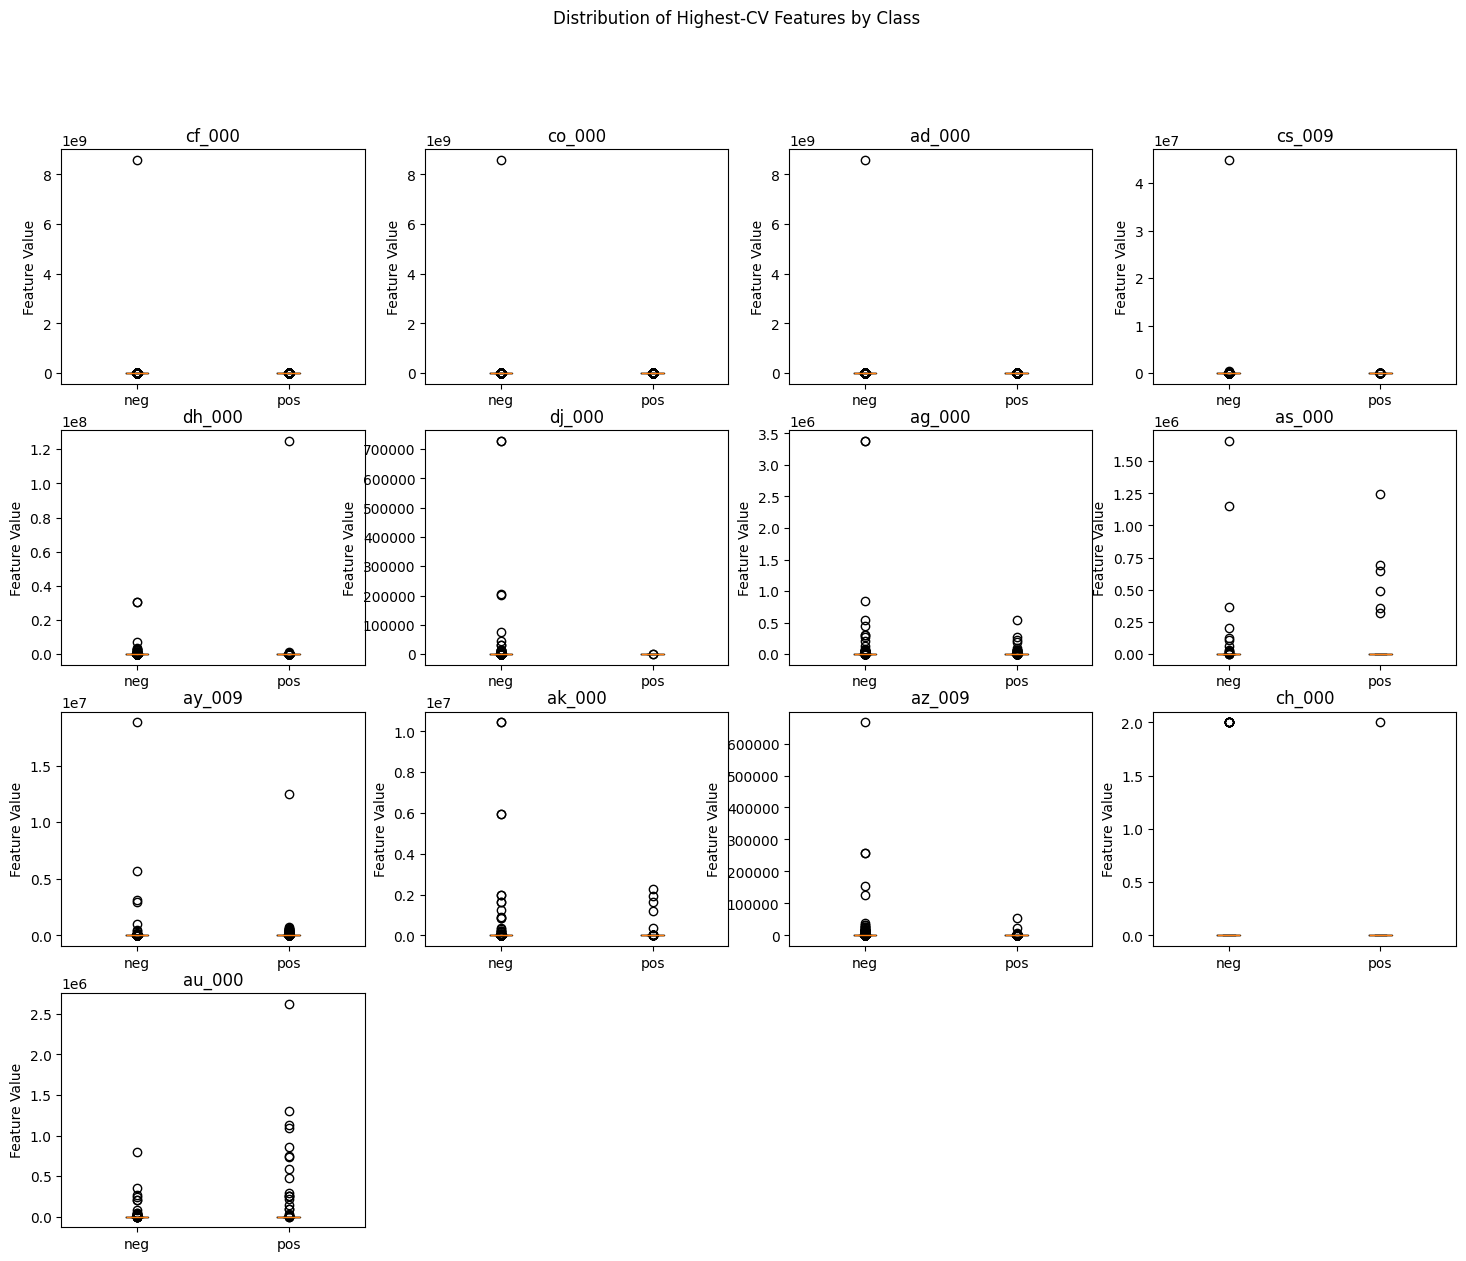

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, feature in zip(axes.flat, top_features):
    values_by_class = [
        x_train.loc[y_train == "neg", feature],
        x_train.loc[y_train == "pos", feature]
    ]
    ax.boxplot(values_by_class)
    ax.set_xticks([1, 2], labels=["neg", "pos"])
    ax.set_title(feature)
    ax.set_ylabel("Feature Value")

for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Distribution of Highest-CV Features by Class")
plt.show()

**Answer**: The plots may show differences between positive and negative cases, but they cannot tell us whether those differences are statistically significant. There are also many more negative cases, which can make the plots harder to interpret. A high CV means a feature varies a lot compared with its average, not that it is useful for predicting failures. I will still use all 170 features in later models.

#### 1(b)(v) - Determine the number of positive and negative data. Is this data set imbalanced?

In [9]:
class_counts = y_train.value_counts().reindex(
    ["neg", "pos"], fill_value=0
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_counts / class_counts.sum() * 100
})

display(class_summary)

,Count,Percentage
class,,
neg,59000,98.333333
pos,1000,1.666667


**Answer**: The training set is very imbalanced. It has 59,000 negative observations and 1000 positive observations. A classifier that always predicts negative would achieve approximately 98.33% accuracy while detecting no positive cases. This means the accuracy alone is insufficient for evaluation model performance.

### 1(c) - Train a random forest to classify the data set. Do NOT compensate for class imbalance in the data set. Calculate the confusion matrix, ROC, AUC, and misclassification for training and test sets and report them (You may use pROC package). Calculate Out of Bag error estimate for your random forset and compare it to the test error.

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight=None,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1,
)

rf_model.fit(x_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


,Error,AUC
Dataset,,
Train,0.000017,1.000000
Test,0.007563,0.992754


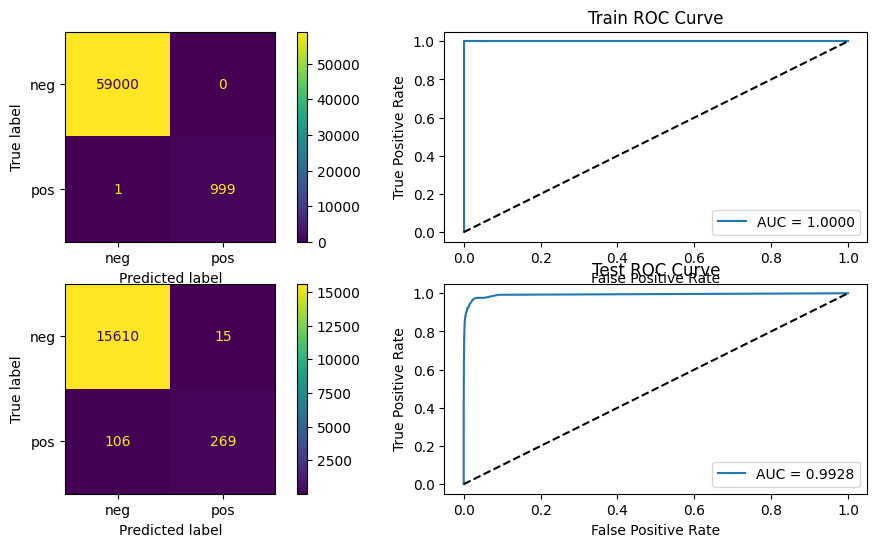

In [11]:
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay
)

positive_index = list(rf_model.classes_).index("pos")

results = []

fig, axes = plt.subplots(2, 2, figsize=(12, 6))

for row, (name, features, labels) in enumerate([
    ("Train", x_train, y_train),
    ("Test", x_test, y_test)
]):
    predictions = rf_model.predict(features)
    probabilities = rf_model.predict_proba(features)[:, positive_index]

    error = 1 - accuracy_score(labels, predictions)
    auc = roc_auc_score(labels, probabilities)
    results.append({"Dataset": name, "Error": error, "AUC": auc})

    matrix = confusion_matrix(labels, predictions, labels=["neg", "pos"])

    ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=["neg", "pos"]).plot(ax=axes[row, 0])

    fpr, tpr, _ = roc_curve(labels, probabilities, pos_label="pos")

    axes[row, 1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[row, 1].plot([0, 1], [0, 1], "k--")
    axes[row, 1].set_xlabel("False Positive Rate")
    axes[row, 1].set_ylabel("True Positive Rate")
    axes[row, 1].set_title(f"{name} ROC Curve")
    axes[row, 1].legend(loc="lower right")

rf_results = pd.DataFrame(results).set_index("Dataset")
display(rf_results)


plt.show()

In [12]:
oob_err = 1 - rf_model.oob_score_
test_error = rf_results.loc["Test", "Error"]

print(f"OOB Error: {oob_err:.4f} ({test_error:.2%})")
print(f"Test Error: {test_error:.4f} ({test_error:.2%})")
print(f"OOB Minus Test Error: {oob_err - test_error:.4f} ({(oob_err - test_error):.2%})")

OOB Error: 0.0061 (0.76%)
Test Error: 0.0076 (0.76%)
OOB Minus Test Error: -0.0014 (-0.14%)


**Answer**: I trained a random forest without balancing the classes. The training error was almost 0% and the training AUC was 1.0, so the model fits the training data almost perfectly. On the test set, the error was 0.76% and the AUC was .9928. The model correctly found 269 of the 375 positive test cases and missed 106, with 15 false positives.

The OOB error was .61%, a little lower than the .76% test error. This means the OOB error was close but slightly optimistic estimate of the test error.

### 1(d) Research how class imbalance is addressed in random forests. Compensate for class imbalance in your random forest and repeat 1c. Compare the results with those of 1c.

In [13]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    oob_score=True,
    random_state=42,
    n_jobs=-1,
    bootstrap=True
)
rf_balanced.fit(x_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


,Error,AUC
Dataset,,
Train,0.000017,1.000000
Test,0.010875,0.991944


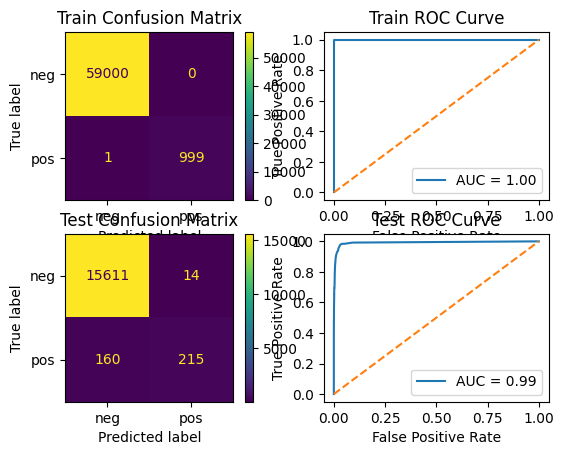

In [14]:
balanced_results = []
fix, axes = plt.subplots(2, 2)

positive_index = list(rf_balanced.classes_).index("pos")

for row, (name, features, labels) in enumerate([
    ("Train", x_train, y_train),
    ("Test", x_test, y_test)
]):
    predictions = rf_balanced.predict(features)
    probabilities = rf_balanced.predict_proba(features)[:, positive_index]

    error = 1 - accuracy_score(labels, predictions)
    auc = roc_auc_score(labels, probabilities)

    balanced_results.append({
        "Dataset": name, 
        "Error": error,
        "AUC": auc
    })

    matrix = confusion_matrix(labels, predictions, labels=["neg", "pos"])
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["neg", "pos"]
    ).plot(ax=axes[row, 0])
    axes[row, 0].set_title(f"{name} Confusion Matrix")

    fpr, tpr, _ = roc_curve(labels, probabilities, pos_label="pos")
    axes[row, 1].plot(fpr, tpr, label=f"AUC = {auc:.2f}")
    axes[row, 1].plot([0, 1], [0, 1], linestyle="--")
    axes[row, 1].set_title(f"{name} ROC Curve")
    axes[row, 1].set_xlabel("False Positive Rate")
    axes[row, 1].set_ylabel("True Positive Rate")
    axes[row, 1].legend()

rf_balanced_results = pd.DataFrame(balanced_results).set_index("Dataset")
display(rf_balanced_results)

plt.show()

In [15]:
display(pd.concat(
    {
        "Unweighted (1c)": rf_results,
        "Weighted (1d)": rf_balanced_results,
    },
    axis=1,
))

oob_comparison = pd.DataFrame({
    "Unweighted (1c)": [1 - rf_model.oob_score_],
    "Weighted (1d)": [1 - rf_balanced.oob_score_],
}, index=["OOB error"])

display(oob_comparison)

Unweighted (1c)           Weighted (1d)          
                  Error       AUC         Error       AUC
Dataset                                                  
Train          0.000017  1.000000      0.000017  1.000000
Test           0.007563  0.992754      0.010875  0.991944

,Unweighted (1c),Weighted (1d)
OOB error,0.006117,0.0082


**Answer**: I handled class imbalance by giving more weight to the positive class. The weighted model found 215 positive cases in the test set, compared with 269 for the unweighted model. Its test AUC was 0.9919, slightly lower than the unweighted model's 0.9928. Its test error was 1.09% compared with .76%. In this case, weighting the classes did not improve the test results.

### 1(e) XGBoost and Model Trees In the case of a univariate tree, only one input dimension is used at a tree split. 

In a multivariate tree, or model tree, at a decision node all input dimensions can be used and thus it is more general. In univariate classification trees, majoritypolling is used at each node to determine the split of that node as the decision rule. In model trees, a (linear) model that relies on all of the variables is used to determine the split of that node (i.e. instead of using Xj > s as the decision rule, one has ∑ j βj Xj > s. as the decision rule). Alternatively, in a regression tree, instead of using average in the region associated with each node, a linear regression model is used to determine the value associated with that node.

One of the methods that can be used at each node is Logistic Regression. Because the number of variables is large in this problem, one can use L1-penalized logistic regression at each node. You can use XGBoost to fit the model tree. Determine α (the regularization term) using cross-validation. Train the model for the APS data set without compensation for class imbalance. Use one of 5 fold, 10 fold, and leave-one-out cross validation methods to estimate the error of your trained model and compare it with the test error. Report the Confusion Matrix, ROC, and AUC for training and test sets.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

y_train_num = y_train.map({"neg": 0, "pos": 1})
y_test_num = y_test.map({"neg": 0, "pos": 1})

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
        n_jobs=2,
    )),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    pipeline,
    param_grid={
        "xgb__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10],
    },
    cv=cv,
    scoring="accuracy",
    n_jobs=1,
    refit=True,
)

search.fit(x_train_raw, y_train_num)

xgb_model = search.best_estimator_

print("Best alpha:", search.best_params_["xgb__reg_alpha"])
print("Best 5-fold CV accuracy:", search.best_score_)
print("Best 5-fold CV error:", 1 - search.best_score_)

Best alpha: 0
Best 5-fold CV accuracy: 0.9931166666666666
Best 5-fold CV error: 0.006883333333333352


,Misclassification rate,AUC
Dataset,,
Train,0.004683,0.996175
Test,0.009312,0.995537


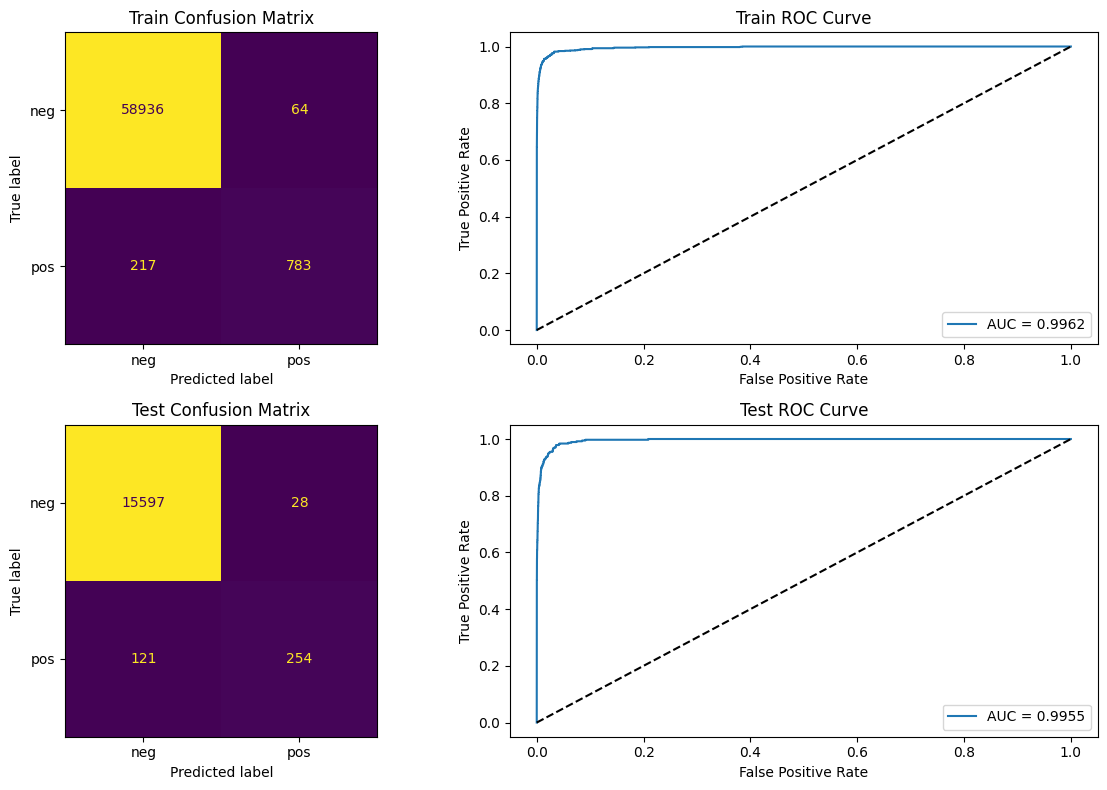

In [17]:
results = []

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (name, features, labels) in enumerate([
    ("Train", x_train_raw, y_train_num),
    ("Test", x_test_raw, y_test_num),
]):
    predictions = xgb_model.predict(features)
    probabilities = xgb_model.predict_proba(features)[:, 1]

    error = 1 - accuracy_score(labels, predictions)
    auc = roc_auc_score(labels, probabilities)

    results.append({
        "Dataset": name,
        "Misclassification rate": error,
        "AUC": auc,
    })

    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(
        matrix,
        display_labels=["neg", "pos"],
    ).plot(ax=axes[row, 0], colorbar=False)
    axes[row, 0].set_title(f"{name} Confusion Matrix")

    fpr, tpr, _ = roc_curve(labels, probabilities)
    axes[row, 1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[row, 1].plot([0, 1], [0, 1], "k--")
    axes[row, 1].set_xlabel("False Positive Rate")
    axes[row, 1].set_ylabel("True Positive Rate")
    axes[row, 1].set_title(f"{name} ROC Curve")
    axes[row, 1].legend()

display(pd.DataFrame(results).set_index("Dataset"))
plt.tight_layout()
plt.show()

**Answer**: I trained an XGBoost model without balancing the classes. I sued 5-fold cross-validation to choose alpha, and the best value was alpha = 0. This means adding an L1 penalty did not improve the cross-validation results.

The 5-fold CV error was .69%, and the test error was 93%. The test error was a little higher, so the CV error was a slightly optimistic estimate, but the two were close. The training error was .47%.

The training AUC was .9962 and the test AUC was .9955. On the test set the model correclty found 254 positive cases and missed 121, with 28 false.

### 1(f) Use SMOTE (Synthetic Minority Over-sampling Technique) to pre-process your data to compensate for class imbalance. Train XGBosst with L1-penalized logistic regression at each node using the pre-processed data and repeat 1e. Do not forget that there is a right and a wrong way of cross validation here. Compare the uncompensated case with SMOTE case.

In [18]:
from sklearn.neighbors import NearestNeighbors

def smote(x, y, k=5, random_state=42):
    rng = np.random.default_rng(random_state)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=int)

    x_min = x[y == 1]
    n_new = int((y ==0).sum() - (y == 1).sum())

    if n_new <= 0:
        return x, y
    
    neighbors = NearestNeighbors(n_neighbors=k + 1).fit(x_min)
    _, neighbors_idx = neighbors.kneighbors(x_min)

    base = rng.integers(0, len(x_min), n_new)
    chosen = neighbors_idx[base, rng.integers(1, k + 1, n_new)]
    gap = rng.random((n_new, 1))

    synthetic = x_min[base] + gap * (x_min[chosen] - x_min[base])
    x_balanced = np.vstack([x, synthetic])
    y_balanced = np.concatenate([y, np.ones(n_new, dtype=int)])

    return x_balanced, y_balanced

In [19]:
def make_xgb(alpha):
    return XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        reg_alpha=alpha,
        random_state=42,
        n_jobs=-1
    )

alphas = [0, 0.001, 0.01, 0.1, 1, 10]
cv_rows = []

for alpha in alphas:
    fold_errors = []

    for fold, (train_indx, val_indx) in enumerate(cv.split(x_train_raw, y_train_num)):
        imputer = SimpleImputer(strategy='median', keep_empty_features=True)
        x_fold_train = imputer.fit_transform(x_train_raw.iloc[train_indx])
        x_val = imputer.transform(x_train_raw.iloc[val_indx])
        y_val = y_train_num.iloc[val_indx]

        x_smote, y_smote = smote(
            x_fold_train,
            y_train_num.iloc[train_indx].to_numpy(),
            random_state=42 + fold
        )

        model = make_xgb(alpha)
        model.fit(x_smote, y_smote)
        predictions = model.predict(x_val)
        fold_errors.append(1 - accuracy_score(y_val, predictions))

    cv_rows.append({
        'alpha': alpha,
        'fold_errors': fold_errors,
        'mean_error': np.mean(fold_errors)
    })

smote_cv_results = pd.DataFrame(cv_rows)
display(smote_cv_results)

best_row = smote_cv_results.loc[smote_cv_results["mean_error"].idxmin()]
best_alpha = best_row["alpha"]
smote_cv_error = best_row["mean_error"]

print(f"Best alpha: {best_alpha}")
print(f"SMOTE CV error: {smote_cv_error}")

,alpha,fold_errors,mean_error
0,0.000,"[0.021583333333333288, 0.020000000000000018, 0...",0.021017
1,0.001,"[0.021583333333333288, 0.020000000000000018, 0...",0.021017
2,0.010,"[0.02183333333333337, 0.02041666666666664, 0.0...",0.021200
3,0.100,"[0.02200000000000002, 0.020166666666666666, 0....",0.021117
4,1.000,"[0.02258333333333329, 0.02041666666666664, 0.0...",0.021450
5,10.000,"[0.021333333333333315, 0.021499999999999964, 0...",0.021600


Best alpha: 0.0
SMOTE CV error: 0.021016666666666683


In [20]:
final_imputer = SimpleImputer(strategy='median', keep_empty_features=True)
x_train_imp = final_imputer.fit_transform(x_train_raw)
x_test_imp = final_imputer.transform(x_test_raw)

x_train_smote, y_train_smote = smote(x_train_imp, y_train_num.to_numpy(), random_state=42)

print("Class counts after SMOTE:", np.bincount(y_train_smote))

xgb_smote = make_xgb(best_alpha)
xgb_smote.fit(x_train_smote, y_train_smote)

Class counts after SMOTE: [59000 59000]


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


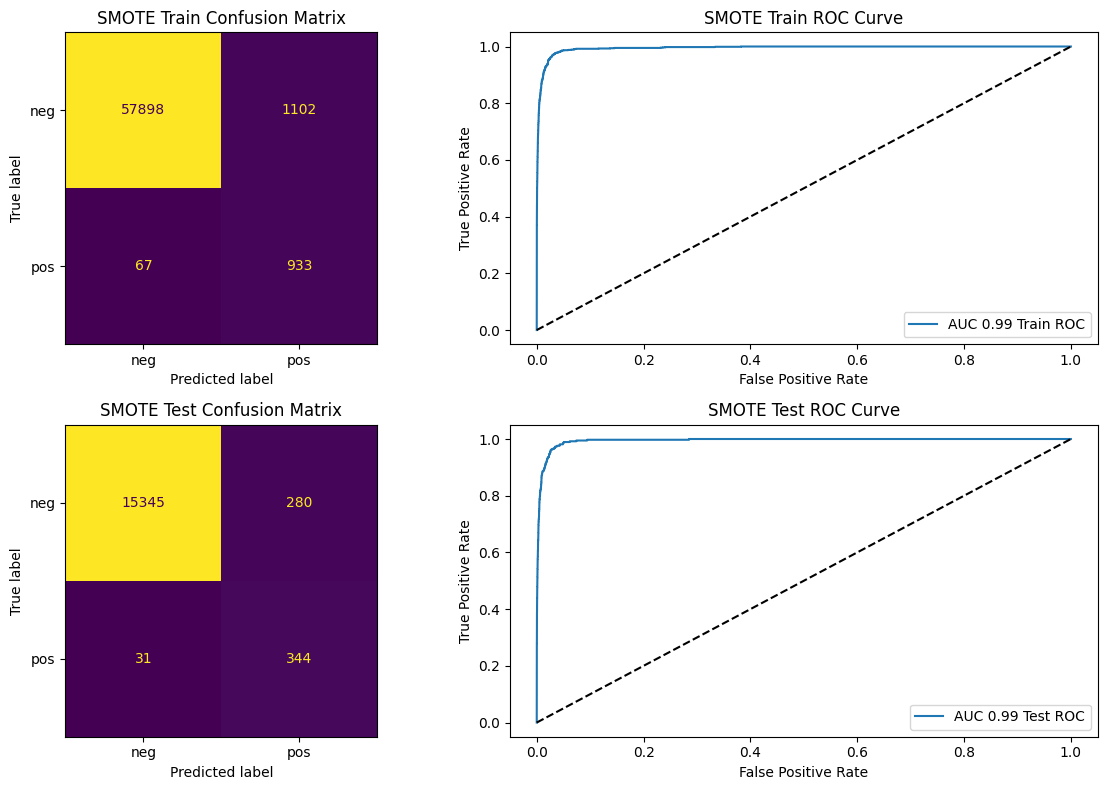

In [21]:
smote_results = []

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (name, features, labels) in enumerate([
    ("Train", x_train_imp, y_train_num.to_numpy()),
    ("Test", x_test_imp, y_test_num.to_numpy())
]):
    predictions = xgb_smote.predict(features)
    probabilities = xgb_smote.predict_proba(features)[:, 1]

    error = 1 - accuracy_score(labels, predictions)
    auc = roc_auc_score(labels, probabilities)

    smote_results.append({
        "Dataset": name,
        "Misclassification rate": error,
        "AUC": auc,
    })

    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["neg", "pos"]).plot(
        ax=axes[row, 0], colorbar=False
    )

    axes[row, 0].set_title(f"SMOTE {name} Confusion Matrix")

    fpr, tpr, _ = roc_curve(labels, probabilities)
    axes[row, 1].plot(fpr, tpr, label=f"AUC {auc:.2f} {name} ROC")
    axes[row, 1].plot([0, 1], [0, 1], "k--")
    axes[row, 1].set_title(f"SMOTE {name} ROC Curve")
    axes[row, 1].set_xlabel("False Positive Rate")
    axes[row, 1].set_ylabel("True Positive Rate")
    axes[row, 1].legend()

plt.tight_layout()
plt.show()

In [22]:
display(pd.concat(
    {
        "No SMOTE (1e)": pd.DataFrame(results).set_index("Dataset"),
        "SMOTE (1f)": pd.DataFrame(smote_results).set_index("Dataset"),
    },
    axis=1,
))

No SMOTE (1e)                       SMOTE (1f)          
        Misclassification rate       AUC Misclassification rate       AUC
Dataset                                                                  
Train                 0.004683  0.996175               0.019483  0.994281
Test                  0.009312  0.995537               0.019437  0.994332

## 2. ISLR 6.6.3 - Suppose we estimate the regression coefficients in a linear regression model by minimizing

**Answer**: As s goes up, the limit on the coefficients gets looser. When s = 0, all the coefficients are 0 and hte model just predicts the mean of y.

### 2(a) - As we increase s from 0, the training RSS will:

**Answer**: 
- iv. steadily decrease
- The bigger s lets the model fit the training data more closely, so the training RSS keepsgoing down.

### 2(b) - Repeat (a) for test RSS.

**Answer**: At first, the extra flexibility helps the model find the real pattern, so test RSS goes down.

### 2(c) Repeat (a) for variance.

**Answer**: When s=0 the model is just a constant, so it has almost no variance.

### 2(d) Repeat (a) for (squared) bias.

**Answer**:  When s is small, th emodel is too simple and has high bias.

### 2(e) Repeat (a) for the irreducible error.

**Answer**: Irreducible error comes from the noise in the data, not from the model



## 3. ISLR, 6.6.5


## 4. ISLR 8.4.5

**Answer**
- Majority vote: each tree votes red if its probability is above .5, andgreen otherwise

- Red votes 0.55, 0.6, 0.6, 0.65, 0.7, 0.75 
    - 6 votes
- Green votes 0.1, 0.15, 0.2, 0.2
    - 4 votes

Red gets more votes, so the final prediction is Red.

- Average probability: add up all 10 probabilites and divide by 10.

The average is .45, which is below .5, so the final prediction is Green.

The two methods disagree. Majority vote only counts which side of .5 eachtree lands on. The average also looks at how sure each treeis. The four green treesare very sure, but the six red trees are only a little above .5


## 5. ISLR 9.7.3


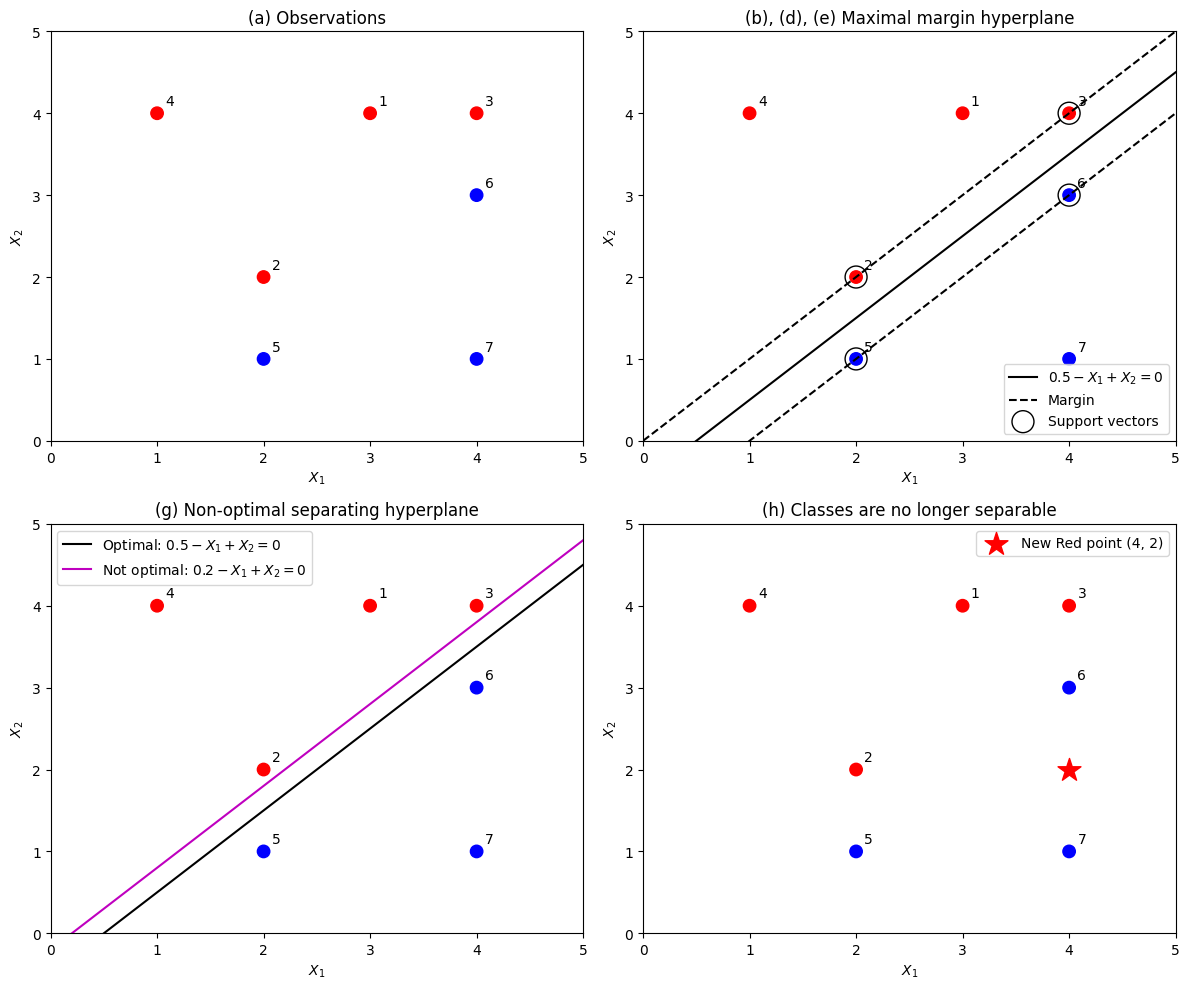

In [23]:
x1 = np.array([3, 2, 4, 1, 2, 4, 4])
x2 = np.array([4, 2, 4, 4, 1, 3, 1])
y_toy = np.array(["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"])

xs = np.linspace(0, 5, 100)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax in axes.flat:
    ax.scatter(x1, x2, c=y_toy, s=80)
    for i, (a, b) in enumerate(zip(x1, x2), start=1):
        ax.annotate(str(i), (a, b), textcoords="offset points", xytext=(6, 6))
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")

axes[0, 0].set_title("(a) Observations")

ax = axes[0, 1]
ax.plot(xs, xs - 0.5, "k-", label="$0.5 - X_1 + X_2 = 0$")
ax.plot(xs, xs, "k--", label="Margin")
ax.plot(xs, xs - 1, "k--")
sv = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
ax.scatter(sv[:, 0], sv[:, 1], s=250, facecolors="none", edgecolors="black", label="Support vectors")
ax.set_title("(b), (d), (e) Maximal margin hyperplane")
ax.legend()

ax = axes[1, 0]
ax.plot(xs, xs - 0.5, "k-", label="Optimal: $0.5 - X_1 + X_2 = 0$")
ax.plot(xs, xs - 0.2, "m-", label="Not optimal: $0.2 - X_1 + X_2 = 0$")
ax.set_title("(g) Non-optimal separating hyperplane")
ax.legend()

ax = axes[1, 1]
ax.scatter([4], [2], c="red", marker="*", s=300, label="New Red point (4, 2)")
ax.set_title("(h) Classes are no longer separable")
ax.legend()

plt.tight_layout()
plt.show()

**Answer: **

(a) - The plot above shows the 7 observations. The red points are mostly in the upper left and the blue points are in the lower right.

(b) - The closest red and blue points come in pairs. Red (2, 2) is right above blue (2, 1) and red (4, 4) is right above Blue (4, 3). The best line goes right betweeneach pair, through (2, 1.5) and (4, 3.5)

0.5 - X1 + X2 = 0

(c) - Classify to red if .5 - x1 + x2 > 0 and classify to blue otherwise

Checking: Red point (2, 2) gives 0.5 - 2 + 2 = 0.5 > 0, and Blue point (2, 1) gives 0.5 - 2 + 1 = -0.5 < 0. 

(d) -  The margin is shown by the dashed lines X2 = X1 and X2 = X1 - 1. The distance from the hyperplane to each dashed line is: 0.354

(e) - The support vectors are the points sitting on the margin lines:
- Red: observation 2 at (2, 2) and observation 3 at (4, 4)
- Blue: observation 5 at (2, 1) and observation 6 at (4, 3)

(f) - Observation 7 at (4, 1) is not a support vector.  The hyperplane only depends on the support vectors, so moving observation 7 a little does not change it, as long as it stays outside the margin.

(g) - It still separates Red from Blue, but it is closer to the Blue points than the Red points, so its margin is smaller. That means it is not the optimal hyperplane.

(h) - Adding a Red point at (4, 2) makes the classes not separable. This point sits right between Blue points (4, 1) and (4, 3), so no straight line can put it on the Red side without also putting one of those Blue points there.